# Case Study 9 — A Shared, Typology-First Mule-Account Model Across Banks: Alert Precision, Cross-Bank Pooling and Generalisation

**Priority:** ★★ Good to have · **Reference:** Case Study 9 — *RBIH MuleHunter.AI: a central-bank-built model to flag mule accounts across banks* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Bank CROs / Heads of Fraud Risk Management, RBIH programme team, AML investigation leads
**Data:** ⚠️ **SYNTHETIC** (D-9-01). Bank account data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs09_mule_typology_alert_precision.ipynb`

## 0. Executive Summary for Business

*(Synthetic data calibrated to RBIH MuleHunter.AI's documented design; RBI disclosed only precision figures. Written after the analysis.)*

- **The question:** should banks use one shared, typology-based model for mule accounts instead of their own rules or models, and what does "90% positive alerts" really mean?
- **Rules drown investigators.** The legacy bank rules flag 6,662 of 144,000 accounts with **4.7% precision** (95% false alarms, worse than the documented "80% false positives"). Most single typology rules are also imprecise when used alone; the "many senders" rule mostly flags genuine traders (2.2% precision).
- **Typology-first design works.** Adding 9 expert typology features to raw account data raises AUC from 0.900 to **0.962** (DeLong p ≈ 1e-60). Precision of the top 500 alerts rises from 75% to **96%**.
- **Pooling across banks beats each bank's own model in 6 of 6 banks** (sign test p = 0.016; PR-AUC +0.08 to +0.20). **A bank that joins with no labels at all** gets *higher* precision from a model trained on the other five banks than from its own labels: +4 to +25 pp. This is the strongest argument for a central model like MuleHunter.
- **"90% precision" is true only at low volume.** The top 500 alerts (0.35% of accounts) are 96% precise but catch only 29% of mules. At 1% of accounts precision falls to 64%. A precision figure means nothing without the alert volume.
  - Precision measured against *confirmed* labels understates it by ~15 pp, because 15% of mules are never confirmed.
  - **A random audit of 139 alerts** verifies the claim within ±5 pp.
- **Limits:**
  - The model largely misses a **typology it has never seen**: recall falls 20–48 pp, and single-pattern mules of an unseen type are almost all missed.
  - It catches only **32% of low-intensity "sleeper" mules** (vs 72% of active ones).
- **₹ (scaled to 10 crore accounts, per 90 days):**
  - At the rules' alert volume, the model catches **4.3× more mules** and stops ≈ ₹850 crore of mule inflow vs ₹196 crore.
  - At the 90%-precision operating point it uses 0.3% of the rules' wasted investigator time (₹0.6 crore vs ₹198 crore) and still stops more (₹300 crore).
- **I recommend:**
  - Adopt the pooled typology model and choose the alert volume per bank by investigator capacity.
  - Verify precision quarterly with random audits.
  - Keep growing the typology library jointly with banks and I4C, because new patterns are the model's blind spot.

## 1. The Problem in Simple English

A **mule account** is a real bank account, often belonging to a student, homemaker or farmer who rented it out or was tricked, through which scammers move stolen money. RBI says mules were behind "53% of the total fraud threats" in 2023. Banks catch them with **rules** ("flag if more than ₹X arrives in Y days"), but rules raise so many false alarms (about **80% wrong**) that investigators drown.

The Reserve Bank Innovation Hub (RBIH) built **MuleHunter.AI** differently:
1. Experts first catalogued **how mules behave** (19 patterns, or "typologies").
2. They built a model on those patterns.
3. They offered **one model to many banks** (26+ by May 2026), reporting **"90 per cent positive alerts"**.

Leaders need to know three things:
- Does typology-first design really beat raw data?
- Does a model pooled across banks beat each bank's own model, including for a bank that joins with no history?
- What does "90% precision" mean, and how should it be verified?

## 2. Reference from the Case File

### (a) What RBIH did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | Mules caused "53% of the total fraud threats to financial institutions" in 2023; bank rule systems produced many false positives |
| Data | "Transaction & account datasets" from partner banks; a pattern library of "**19 distinct patterns** of mule account activity" (later "90 fraud patterns") |
| Approach | Study typologies with partner banks → AI/ML models → pilot with two PSBs → roll out across banks |
| Statistics | Peak mule activity "**11 PM–1 AM**". Other statistics: ND |
| ML / metric | "AI and machine learning algorithms" (unspecified); "**90 per cent positive alerts**" vs "**80 per cent false positives**" on competing platforms |
| Adoption | 6 banks (Aug 2025) → 23 (Dec 2025) → 26+ (May 2026) + MoU with I4C |
| Impact | Precision only; RBI declined an RTI request for the number of mule accounts detected |

**Sources:** Business Standard, 9 Dec 2024 and 1 Aug 2025; MediaNama, 30 Dec 2025; ClearingPost, May 2026 (links in the reference file and the appendix).

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 144,000 accounts at **6 banks** (rural PSBs, a private bank, an SFB and a late-joining RRB), ≈ 1.1% true mules showing 1–3 of **8 expert typologies** (a subset of the 19), 40% low-intensity "sleepers"; realistic hard negatives (traders, farmers, gig workers); only 85% of mules are ever confirmed. Plus a 28,800-row transaction-hour sample. |
| Statistics added | Circular statistics for the 11 PM–1 AM claim; typology rule precision and lift with Holm; bank × typology heterogeneity (χ², Cramér's V); typology-first vs raw (DeLong, precision at k with bootstrap); pooled vs bank-own models (paired across banks, I² heterogeneity); leave-one-bank-out and leave-one-typology-out generalisation; label-noise correction and an **audit-sample design** to verify "90% precision" |

### (c) How the industry uses this

Every Indian bank now runs mule-detection programmes (RBI's 2024–25 mule-account push; NPCI and I4C's suspect registry; Federal Bank, Kotak and Paytm Payments Bank in-house models; see Case 8). **Typology libraries** are the AML industry's standard (FATF and FIU-IND red-flag indicators), and **consortium models** across institutions are the trend globally (UK's Pay.UK, SWIFT's anomaly service, Mastercard Consumer Fraud Risk). The questions here (do shared models transfer? how to verify precision?) are what every adopting bank's model-risk team must answer.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Should a bank adopt a shared, typology-based mule model instead of its own rules or its own model? |
| Analytical | (1) Do typology features add discrimination beyond raw account data? (2) Does pooling across banks beat bank-own models, including for a bank with no labels? (3) What alert precision is achievable at a workable alert volume, and how do we verify it? |

**Hypotheses**
- **H1 (night activity):** H0: mule and genuine transaction hours have the same distribution (Kolmogorov–Smirnov on hours; Rayleigh test of a preferred direction; two-proportion test for the 23:00–01:00 share).
- **H2 (typology-first):** H0: AUC(raw + typologies) = AUC(raw) (DeLong); precision@k equal (paired bootstrap).
- **H3 (pooling):** H0: per-bank PR-AUC of the pooled model = bank-own model (paired across 6 banks: bootstrap per bank; sign test across banks).
- **H4 (transfer):** a model trained on 5 banks achieves on the 6th bank a precision@k within 10 pp of a model trained on that bank's own labels.

**Primary metric:** **alert precision** (the documented headline) at a fixed alert volume per bank. **Secondary:** recall of true mules at that volume; PR-AUC. **Guardrail:** alerts per investigator-day must not exceed capacity. **Evaluation truth:** we evaluate against **true** mule status (hidden), and separately show what a bank would *see* using only confirmed labels.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.metrics import roc_auc_score, average_precision_score
from statsmodels.stats.proportion import proportion_confint, proportions_ztest
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public labelled mule-account data | **None.** Bank account data are confidential; RBIH declined even aggregate counts under RTI. |
| Synthetic AML benchmarks (IBM AMLworld on GitHub/Kaggle) | Transaction-level laundering, not account-level mule typologies across banks; Kaggle-hosted. Not used. |
| **Decision** | Synthetic account aggregates for 6 banks with 8 expert typologies (D-9-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs09.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 9 (RBIH MuleHunter.AI-style cross-bank mule detection)
===========================================================================================
THIS DATA IS SYNTHETIC. Bank account and transaction data are confidential.

Six partner banks (2 large public-sector banks with rural/semi-urban books, 1 mid PSB, 1 private bank,
1 small finance bank, 1 late-joining regional bank) submit 90-day account aggregates. Mule accounts
follow 8 expert TYPOLOGIES (a subset of the documented "19 distinct patterns"):
  T1 rapid pass-through      T2 fan-in from many senders   T3 dormant-account reactivation
  T4 new account, big inflow T5 cash-out in round amounts  T6 device / SIM churn
  T7 late-night activity     T8 inflow far above declared income/occupation
Each mule shows 1-3 typologies; 30% are low-intensity "sleepers". Genuine hard negatives:
small traders (many senders), farmers/pensioners (cash withdrawals), gig workers (night activity),
students receiving from family, dormant accounts genuinely reactivated.
Labels: confirmed mule (investigation / I4C complaint); ~15% of true mules are never confirmed.

Calibration anchors (reference file, Case Study 9): "19 distinct patterns"; peak mule activity
"11 PM-1 AM"; rule systems "80 per cent false positives"; MuleHunter "90 per cent positive alerts";
mules "53% of the total fraud threats". Sizes/rates are our assumptions (decision.md D-9-02).
Hidden truth columns start with "_".

Outputs: data/cs09/accounts.csv.gz, data/cs09/txn_hour_sample.csv.gz
"""
import os
import numpy as np
import pandas as pd

SEED = 42
BANKS = {  # name: (accounts, mule_rate, occupation mix [salaried, trader, student, homemaker, farmer, gig, pensioner], typology weights T1..T8)
    "PSB-A (large, rural)":   (40_000, 0.010, [0.22, 0.14, 0.10, 0.14, 0.24, 0.06, 0.10], [1, 1, 3, 1, 3, 1, 1, 3]),
    "PSB-B (large, semi-urban)": (36_000, 0.012, [0.28, 0.16, 0.12, 0.12, 0.14, 0.08, 0.10], [2, 2, 2, 1, 2, 1, 1, 2]),
    "PSB-C (mid)":            (20_000, 0.011, [0.30, 0.15, 0.12, 0.10, 0.12, 0.10, 0.11], [2, 2, 2, 2, 2, 1, 1, 2]),
    "Private-D (urban)":      (22_000, 0.008, [0.45, 0.14, 0.14, 0.06, 0.02, 0.15, 0.04], [3, 3, 1, 2, 1, 2, 2, 1]),
    "SFB-E (small finance)":  (14_000, 0.016, [0.20, 0.28, 0.10, 0.12, 0.12, 0.12, 0.06], [2, 3, 1, 3, 2, 2, 1, 2]),
    "RRB-F (late joiner)":    (12_000, 0.014, [0.18, 0.12, 0.12, 0.16, 0.26, 0.08, 0.08], [1, 1, 2, 1, 2, 3, 3, 2]),
}
OCC = ["salaried", "trader", "student", "homemaker", "farmer", "gig_worker", "pensioner"]
INC = dict(zip(OCC, [45000, 60000, 3000, 5000, 15000, 22000, 25000]))


def generate(seed=SEED):
    rng = np.random.default_rng(seed)
    out = []
    for b, (n, mr, occ_p, tw) in BANKS.items():
        occ = rng.choice(OCC, n, p=np.array(occ_p) / sum(occ_p))
        is_m = rng.random(n) < mr
        # mules are recruited disproportionately among students, homemakers, farmers, gig workers
        rec = is_m & (rng.random(n) < 0.6); occ[rec] = rng.choice(["student", "homemaker", "farmer", "gig_worker"], rec.sum(), p=[0.4, 0.25, 0.2, 0.15])
        inc = np.array([INC[o] for o in occ]) * np.exp(rng.normal(0, 0.6, n))
        f = lambda o: (occ == o)
        mult = 3 * np.exp(rng.normal(0, 0.6, n)) * np.where(f("trader"), 2.5, 1) * np.where(rng.random(n) < 0.03, rng.uniform(4, 20, n), 1)   # 3%: one-off big credit (land sale, loan)
        credits = inc * mult
        n_cr = np.maximum(1, rng.poisson(np.select([f("trader"), f("gig_worker"), f("salaried")], [120, 55, 5], 8)))
        senders = np.maximum(1, rng.poisson(np.select([f("trader"), f("gig_worker"), f("student")], [38, 14, 2], 3) * np.exp(rng.normal(0, 0.5, n))))
        pass_thr = np.clip(rng.beta(9, 1.6, n) * np.where(f("trader") | f("gig_worker"), 1.0, 0.97), 0, 1.2)
        hold_h = np.exp(rng.normal(np.log(np.where(f("trader"), 40, 200)), 1.2))
        cash = np.clip(rng.beta(2, 8, n) + np.where(f("farmer") | f("pensioner"), 0.35, 0), 0, 1)
        round_sh = np.clip(rng.beta(2, 7, n) + np.where(f("farmer") | f("pensioner"), 0.2, 0), 0, 1)
        night = np.clip(rng.beta(1.5, 40, n) + np.where(f("gig_worker"), 0.10, 0), 0, 1)
        devices = 1 + rng.binomial(2, 0.15, n); sim = (rng.random(n) < 0.03).astype(int)
        dormant = np.where(rng.random(n) < 0.05, rng.uniform(180, 900, n), rng.uniform(0, 20, n))
        age_days = np.where(rng.random(n) < 0.08, rng.uniform(10, 180, n), rng.uniform(180, 6000, n))
        # ---------- mule typologies ----------
        typ = np.full(n, "", dtype=object); idx = np.flatnonzero(is_m)
        sleeper = rng.random(n) < 0.40
        w = np.array(tw, float) / sum(tw)
        for i in idx:
            k = rng.choice([1, 2, 3], p=[0.4, 0.4, 0.2]); ts_ = rng.choice(8, k, replace=False, p=w); typ[i] = "|".join(f"T{t + 1}" for t in sorted(ts_))
            s = 0.35 if sleeper[i] else 1.0                                   # sleepers show weaker patterns
            credits[i] *= 1 + s * rng.uniform(0.3, 2.5)
            for t in ts_:
                if t == 0: pass_thr[i] = 1 - s * rng.uniform(0.0, 0.03) - (1 - s) * 0.05; hold_h[i] = np.exp(np.log(hold_h[i]) * (1 - s) + s * np.log(rng.uniform(1, 8)))
                if t == 1: senders[i] = int(senders[i] + s * rng.uniform(15, 90)); n_cr[i] = int(n_cr[i] + s * rng.uniform(30, 200))
                if t == 2: dormant[i] = s * rng.uniform(200, 900) + (1 - s) * dormant[i]
                if t == 3: age_days[i] = s * rng.uniform(10, 90) + (1 - s) * age_days[i]
                if t == 4: cash[i] = cash[i] * (1 - s) + s * rng.uniform(0.6, 0.95); round_sh[i] = round_sh[i] * (1 - s) + s * rng.uniform(0.6, 0.9)
                if t == 5: devices[i] = devices[i] + int(round(s * rng.integers(2, 6))); sim[i] = int(rng.random() < 0.3 + 0.6 * s)
                if t == 6: night[i] = night[i] * (1 - s) + s * rng.uniform(0.25, 0.6)
                if t == 7: credits[i] = credits[i] * (1 + s * rng.uniform(2, 10))
        debits = credits * pass_thr
        bal = np.maximum(0, credits / 3 * (1.05 - pass_thr) * np.exp(rng.normal(0, 0.5, n)) + rng.uniform(0, 3000, n))
        # labels: 85% of true mules confirmed (investigation / I4C complaint), bank-specific
        conf = is_m & (rng.random(n) < 0.85)
        out.append(pd.DataFrame({"bank": b, "account_id": [f"{b[:5].replace(' ', '').replace('(', '')}-{i:06d}" for i in range(n)],
                                 "occupation": occ, "declared_income_monthly": np.round(inc, -2), "customer_age": np.clip(rng.normal(36, 13, n), 18, 85).round(),
                                 "kyc_type": np.where(rng.random(n) < np.where(is_m, 0.35, 0.12), "minimum_kyc", "full_kyc"),
                                 "account_age_days": age_days.round(), "dormant_days_before": dormant.round(),
                                 "credits_90d_inr": np.round(credits, -1), "debits_90d_inr": np.round(debits, -1), "n_credits_90d": n_cr,
                                 "avg_balance_inr": np.round(bal, -1), "distinct_senders_30d": senders, "median_hold_hours": hold_h.round(1),
                                 "cash_withdrawal_share": cash.round(3), "round_amount_share": round_sh.round(3), "night_share_23_01": night.round(3),
                                 "n_devices_30d": devices, "sim_change_30d": sim, "confirmed_mule": conf.astype(int),
                                 "_is_mule": is_m.astype(int), "_typologies": typ, "_sleeper": (sleeper & is_m).astype(int)}))
    df = pd.concat(out, ignore_index=True)
    # data-quality defects
    df.loc[df.sample(frac=0.05, random_state=seed).index, "declared_income_monthly"] = np.nan        # income not captured (old KYC)
    df = pd.concat([df, df[df.bank == "PSB-B (large, semi-urban)"].sample(n=600, random_state=seed + 1)], ignore_index=True)  # double submission
    df.loc[df.sample(n=200, random_state=seed + 2).index, "night_share_23_01"] = 1.7                 # impossible share (unit bug: % / 60)
    # transaction-hour sample for the "11 PM - 1 AM" analysis
    m = df[df._is_mule == 1].drop_duplicates("account_id").sample(1200, random_state=seed); g = df[df._is_mule == 0].drop_duplicates("account_id").sample(1200, random_state=seed)
    hrs = []
    for lab, d in ((1, m), (0, g)):
        for acc, ns in zip(d.account_id, d.night_share_23_01.clip(0, 1)):
            k = 12; night_n = rng.binomial(k, min(0.95, ns * 2.2 + (0.25 if lab else 0)))
            h_n = (np.round(rng.vonmises(0, 6.0, night_n) / (2 * np.pi) * 24 * 60) % 1440) / 60            # centred on midnight
            h_d = (np.round(rng.vonmises(np.pi * 13 / 12, 1.4, k - night_n) / (2 * np.pi) * 24 * 60) % 1440) / 60  # centred on 13:00
            for h in np.r_[h_n, h_d]: hrs.append((acc, lab, round(float(h), 3)))
    hours = pd.DataFrame(hrs, columns=["account_id", "_is_mule", "txn_hour_decimal"])
    return df, hours


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs09"), exist_ok=True)
    d, h = generate(); d.to_csv(os.path.join(here, "cs09", "accounts.csv.gz"), index=False); h.to_csv(os.path.join(here, "cs09", "txn_hour_sample.csv.gz"), index=False)
    dd = d.drop_duplicates("account_id")
    print(len(dd), "accounts | mules", dd._is_mule.sum(), "confirmed", dd.confirmed_mule.sum())
    print(dd.groupby("bank")._is_mule.mean().round(4).to_dict())
    print(len(h), "hour rows")

Overwriting data/generate_cs09.py


In [3]:
os.makedirs("data/cs09", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs09 as gen; importlib.reload(gen)
raw, hours = gen.generate(seed=SEED)
raw.to_csv("data/cs09/accounts.csv.gz", index=False); hours.to_csv("data/cs09/txn_hour_sample.csv.gz", index=False)
print(f"{len(raw):,} account rows | {raw.account_id.nunique():,} unique accounts | {len(hours):,} transaction-hour rows")
raw.drop(columns=[c for c in raw.columns if c.startswith("_")]).sample(3, random_state=SEED).T

144,600 account rows | 144,000 unique accounts | 28,800 transaction-hour rows


,42302,87560,39010
bank,"PSB-B (large, semi-urban)",PSB-C (mid),"PSB-A (large, rural)"
account_id,PSB-B-002302,PSB-C-011560,PSB-A-039010
occupation,salaried,farmer,homemaker
declared_income_monthly,NaN,"25,800.0000","2,400.0000"
customer_age,25.0000,56.0000,43.0000
kyc_type,full_kyc,full_kyc,minimum_kyc
account_age_days,"4,100.0000","3,790.0000","3,446.0000"
dormant_days_before,8.0000,10.0000,9.0000
credits_90d_inr,"204,830.0000","42,950.0000","13,460.0000"
debits_90d_inr,"156,720.0000","34,440.0000","8,390.0000"


| Parameter | Value | Basis |
|---|---|---|
| Banks | 6: PSB-A 40k, PSB-B 36k, PSB-C 20k, Private-D 22k, SFB-E 14k, RRB-F 12k accounts; different occupation mixes | **Documented**: pilots with PSBs, then wider roll-out; sizes ours |
| Mule prevalence | 0.8%–1.6% by bank | Our assumption |
| Typologies | T1 pass-through · T2 fan-in · T3 dormant reactivation · T4 new account big inflow · T5 round-amount cash-out · T6 device/SIM churn · T7 night activity · T8 inflow ≫ declared income; bank-specific mix | **Documented**: "19 distinct patterns"; "11 PM–1 AM" |
| Difficulty | 40% sleepers (35% intensity); 3% genuine one-off big credits; traders (many senders), farmers/pensioners (cash), gig workers (night) | Realism |
| Labels | 85% of true mules confirmed; the rest look "genuine" in the labels | Realism (investigations are incomplete) |
| DQ issues | 600 duplicate rows (double submission by PSB-B); 5% missing declared income; 200 impossible night shares (> 1) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("bank, account_id", "Partner bank and account"), ("occupation, declared_income_monthly, customer_age, kyc_type", "KYC profile (income 5% missing)"),
    ("account_age_days, dormant_days_before", "Account vintage; days dormant before the 90-day window"),
    ("credits_90d_inr, debits_90d_inr, n_credits_90d, avg_balance_inr", "Raw 90-day aggregates (what every bank has)"),
    ("distinct_senders_30d, median_hold_hours", "Fan-in and how long money stays"), ("cash_withdrawal_share, round_amount_share", "Cash-out behaviour"),
    ("night_share_23_01", "Share of transactions between 11 PM and 1 AM"), ("n_devices_30d, sim_change_30d", "Device / SIM churn"),
    ("confirmed_mule", "Label available to the bank (investigation / I4C complaint)"), ("_is_mule, _typologies, _sleeper", "HIDDEN truth (evaluation only)"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs09/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"bank, account_id",Partner bank and account
1,"occupation, declared_income_monthly, customer_...",KYC profile (income 5% missing)
2,"account_age_days, dormant_days_before",Account vintage; days dormant before the 90-da...
3,"credits_90d_inr, debits_90d_inr, n_credits_90d...",Raw 90-day aggregates (what every bank has)
4,"distinct_senders_30d, median_hold_hours",Fan-in and how long money stays
5,"cash_withdrawal_share, round_amount_share",Cash-out behaviour
6,night_share_23_01,Share of transactions between 11 PM and 1 AM
7,"n_devices_30d, sim_change_30d",Device / SIM churn
8,confirmed_mule,Label available to the bank (investigation / I...
9,"_is_mule, _typologies, _sleeper",HIDDEN truth (evaluation only)


## 5. Data Quality Checks

In [5]:
df = pd.read_csv("data/cs09/accounts.csv.gz", keep_default_na=True)
hr = pd.read_csv("data/cs09/txn_hour_sample.csv.gz")
checks = {"duplicate account_id (double submission)": int(df.account_id.duplicated().sum()), "declared income missing": int(df.declared_income_monthly.isna().sum()),
          "night share > 1 (unit bug)": int((df.night_share_23_01 > 1).sum()), "debits > 1.2 × credits": int((df.debits_90d_inr > 1.2 * df.credits_90d_inr).sum()),
          "confirmed but not a true mule (false confirmations)": int(((df.confirmed_mule == 1) & (df._is_mule == 0)).sum()),
          "true mules never confirmed": int(((df.confirmed_mule == 0) & (df._is_mule == 1))[~df.account_id.duplicated()].sum())}
print(pd.Series(checks, name="rows").to_string())
df = df.drop_duplicates("account_id").reset_index(drop=True)
df.loc[df.night_share_23_01 > 1, "night_share_23_01"] = np.nan
occ_med = df.groupby("occupation").declared_income_monthly.transform("median")
df["income_missing"] = df.declared_income_monthly.isna().astype(int); df["income_filled"] = df.declared_income_monthly.fillna(occ_med)
df["inflow_to_income"] = df.credits_90d_inr / 3 / df.income_filled
df["pass_through"] = df.debits_90d_inr / df.credits_90d_inr
df["kyc_min"] = (df.kyc_type == "minimum_kyc").astype(int); df["occ_c"] = df.occupation.astype("category").cat.codes
print(f"\nClean: {len(df):,} accounts | true mules {df._is_mule.sum():,} ({df._is_mule.mean():.2%}) | confirmed {df.confirmed_mule.sum():,} | "
      f"label coverage {df.confirmed_mule[df._is_mule == 1].mean():.0%}")
df.groupby("bank").agg(accounts=("account_id", "size"), true_mule_rate=("_is_mule", "mean"), confirmed=("confirmed_mule", "sum"))

duplicate account_id (double submission)                600
declared income missing                                7226
night share > 1 (unit bug)                              200
debits > 1.2 × credits                                    0
confirmed but not a true mule (false confirmations)       0
true mules never confirmed                              255



Clean: 144,000 accounts | true mules 1,691 (1.17%) | confirmed 1,436 | label coverage 85%


,accounts,true_mule_rate,confirmed
bank,,,
"PSB-A (large, rural)",40000,0.0102,346
"PSB-B (large, semi-urban)",36000,0.0126,382
PSB-C (mid),20000,0.0115,200
Private-D (urban),22000,0.0082,156
RRB-F (late joiner),12000,0.0144,149
SFB-E (small finance),14000,0.0176,203


**Observation:** we removed **600 duplicate accounts** (PSB-B submitted a file twice), set **200 impossible night shares (> 1, a unit bug) to missing**, and filled **7,226 missing declared incomes (5%)** with the occupation median, keeping an "income missing" flag so the model can learn whether missingness itself is informative. There are no false confirmations, but **255 true mules (15%) were never confirmed**: the labels banks train on are incomplete. Clean: **144,000 accounts, 1,691 true mules (1.17%), 1,436 confirmed**. Mule prevalence ranges from 0.82% (Private-D) to 1.76% (SFB-E).

## 6. Exploratory Data Analysis

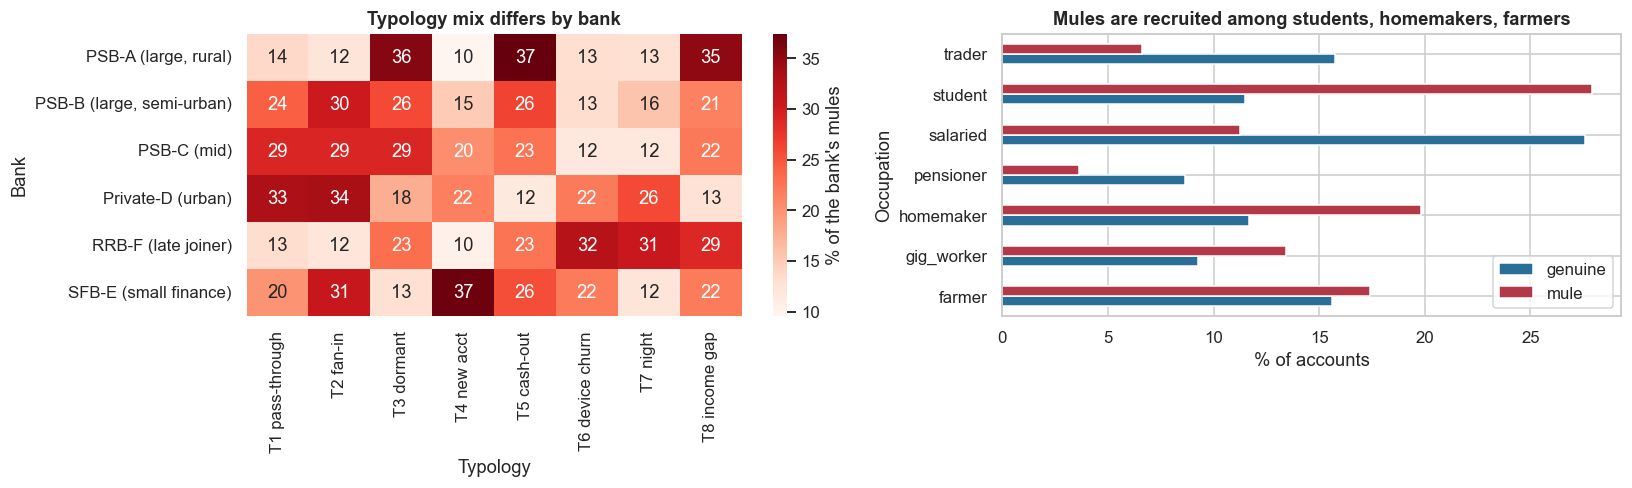

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
mu = df[df._is_mule == 1].copy(); T = [f"T{i}" for i in range(1, 9)]
TNAME = dict(zip(T, ["T1 pass-through", "T2 fan-in", "T3 dormant", "T4 new acct", "T5 cash-out", "T6 device churn", "T7 night", "T8 income gap"]))
tm = pd.DataFrame({TNAME[t]: mu._typologies.str.contains(t + r"\b", regex=True) for t in T}); tm["bank"] = mu.bank.values
sns.heatmap(tm.groupby("bank").mean() * 100, annot=True, fmt=".0f", cmap="Reds", ax=axes[0], cbar_kws={"label": "% of the bank's mules"})
axes[0].set_title("Typology mix differs by bank"); axes[0].set_xlabel("Typology"); axes[0].set_ylabel("Bank")
occ = pd.crosstab(df.occupation, df._is_mule, normalize="columns") * 100; occ.columns = ["genuine", "mule"]
occ.plot(kind="barh", ax=axes[1], color=["#2a6f97", "#b23a48"]); axes[1].set_xlabel("% of accounts"); axes[1].set_ylabel("Occupation")
axes[1].set_title("Mules are recruited among students, homemakers, farmers")
plt.tight_layout(); plt.show()

**Takeaway:** **left:** the typology mix differs across banks. Rural PSB-A's mules are dominated by **dormant-account reactivation, cash-out and income-gap** patterns; the urban private bank's by **pass-through and fan-in**; the late-joining RRB-F by **device churn and night activity**. **Right:** mules are drawn disproportionately from **students, homemakers, farmers and gig workers**, the "recruited" profile RBI describes. Occupation alone is a weak signal, since most of those people are genuine. Both facts matter: a single bank sees only part of the pattern library, which is the case for pooling (7.4).

## 7. Statistical Analysis (core section)

### 7.1 Testing the documented "peak mule activity is 11 PM – 1 AM"

**(a) Why circular statistics?** Hours wrap around: 23:30 and 00:30 are one hour apart, not 23. Ordinary means and t-tests are wrong for clock times. We convert hours to angles and compute the **circular mean** and **mean resultant length R** (0 = spread evenly, 1 = all at one time), with the **Rayleigh test** for a preferred time of day. Group differences use the **two-sample KS test** on hours. To respect clustering (12 transactions per account), the 23:00–01:00 share is compared **per account** with Mann–Whitney.

KS (hour distributions differ): D = 0.161, p = 1.3e-163 | per-account 23–01 share: Mann–Whitney p = 3.9e-188, rank-biserial = 0.67


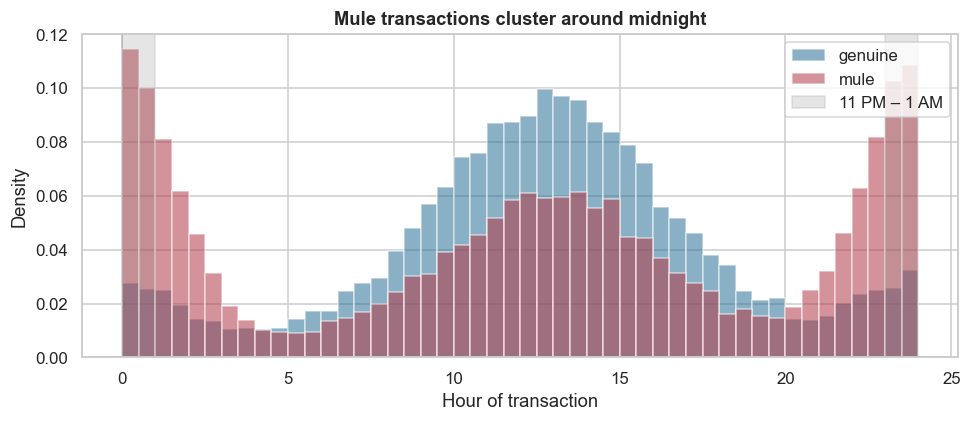

,txns,accounts,circular mean time,R (concentration),Rayleigh p,share 23:00–01:00,modal hour
group,,,,,,,
genuine,14400,1200,13:07,0.4296,0.0000,0.0556,13
mule,14400,1200,21:14,0.1198,0.0000,0.2130,0


In [7]:
def circ(h):
    a = h / 24 * 2 * np.pi; C, S = np.cos(a).mean(), np.sin(a).mean(); R = np.hypot(C, S); n = len(a)
    mean_h = (np.arctan2(S, C) % (2 * np.pi)) / (2 * np.pi) * 24; z = n * R ** 2
    p = np.exp(-z) * (1 + (2 * z - z ** 2) / (4 * n) - (24 * z - 132 * z ** 2 + 76 * z ** 3 - 9 * z ** 4) / (288 * n ** 2))
    return mean_h, R, max(p, 0)
rows = []
for lab, g in hr.groupby("_is_mule"):
    mh, R, p = circ(g.txn_hour_decimal.values); win = ((g.txn_hour_decimal >= 23) | (g.txn_hour_decimal < 1)).mean()
    peak = g.txn_hour_decimal.astype(int).value_counts().idxmax()
    rows.append(("mule" if lab else "genuine", len(g), g.account_id.nunique(), f"{int(mh):02d}:{int(mh % 1 * 60):02d}", R, p, win, peak))
ct = pd.DataFrame(rows, columns=["group", "txns", "accounts", "circular mean time", "R (concentration)", "Rayleigh p", "share 23:00–01:00", "modal hour"]).set_index("group")
ks = stats.ks_2samp(hr[hr._is_mule == 1].txn_hour_decimal, hr[hr._is_mule == 0].txn_hour_decimal)
acc_share = hr.assign(w=(hr.txn_hour_decimal >= 23) | (hr.txn_hour_decimal < 1)).groupby(["account_id", "_is_mule"]).w.mean().reset_index()
mw = stats.mannwhitneyu(acc_share[acc_share._is_mule == 1].w, acc_share[acc_share._is_mule == 0].w)
rbc = 2 * mw.statistic / ((acc_share._is_mule == 1).sum() * (acc_share._is_mule == 0).sum()) - 1
print(f"KS (hour distributions differ): D = {ks.statistic:.3f}, p = {ks.pvalue:.2g} | per-account 23–01 share: Mann–Whitney p = {mw.pvalue:.2g}, rank-biserial = {rbc:.2f}")
fig, ax = plt.subplots(figsize=(9, 4))
for lab, c_, nm in ((0, "#2a6f97", "genuine"), (1, "#b23a48", "mule")):
    ax.hist(hr[hr._is_mule == lab].txn_hour_decimal, bins=48, range=(0, 24), density=True, alpha=0.55, color=c_, label=nm)
ax.axvspan(23, 24, color="grey", alpha=0.2); ax.axvspan(0, 1, color="grey", alpha=0.2, label="11 PM – 1 AM")
ax.set_xlabel("Hour of transaction"); ax.set_ylabel("Density"); ax.set_title("Mule transactions cluster around midnight"); ax.legend(); plt.tight_layout(); plt.show()
ct.round(4)

**Takeaway:** - **The documented claim holds:** mule transactions differ from genuine ones (KS D = 0.16, p ≈ 1e-163). **21.3% of mule transactions fall between 11 PM and 1 AM vs 5.6% for genuine accounts.** Per account, mules have a much higher late-night share (Mann–Whitney p ≈ 1e-188, rank-biserial 0.67, a large effect). The **modal hour for mules is midnight**, for genuine customers 1 PM.
- **A statistical warning:** the mule *circular mean* (21:14) is misleading. Mule activity is **bimodal** (a midnight cluster plus ordinary daytime use), so the average falls in between, and its concentration is low (R = 0.12 vs 0.43 for genuine). For multi-peaked clock data, report the mode and the share in a window, not the mean.
- **(f) Business meaning:** a night-activity feature is genuinely useful, but most mule transactions still happen in the day. It cannot be used alone.

### 7.2 The typology library as rules: precision, coverage and lift of each pattern

**(a) Why?** Typology-first modelling starts with experts. Before any model, each typology becomes a transparent rule. We measure **precision** (share of flagged accounts that are true mules, with a Wilson CI), **coverage** (share of mules flagged) and **lift**, using χ² and Holm across the 8 rules. We also measure the bank's legacy rule set, the "80% false positives" baseline.

In [8]:
TRULE = {"T1 pass-through": (df.pass_through > 0.97) & (df.median_hold_hours < 12),
         "T2 fan-in": df.distinct_senders_30d > 40,
         "T3 dormant": (df.dormant_days_before > 180) & (df.credits_90d_inr > 1e5),
         "T4 new acct": (df.account_age_days < 90) & (df.credits_90d_inr > 1.5e5),
         "T5 cash-out": (df.cash_withdrawal_share > 0.6) & (df.round_amount_share > 0.55),
         "T6 device churn": (df.n_devices_30d >= 3) & (df.sim_change_30d == 1),
         "T7 night": df.night_share_23_01 > 0.2,
         "T8 income gap": df.inflow_to_income > 12}
LEGACY = ((df.inflow_to_income > 15) & (df.credits_90d_inr > 2e5)) | (df.distinct_senders_30d > 60) | ((df.cash_withdrawal_share > 0.8) & (df.credits_90d_inr > 5e5)) | ((df.account_age_days < 60) & (df.credits_90d_inr > 3e5))
y = df._is_mule.values; rows = []
for nm, m in list(TRULE.items()) + [("ANY typology rule", pd.concat(TRULE, axis=1).any(axis=1)), ("legacy bank rules", LEGACY)]:
    m = m.fillna(False).values; tp = (m & (y == 1)).sum(); lo, hi = proportion_confint(tp, max(m.sum(), 1), method="wilson")
    p = stats.chi2_contingency(pd.crosstab(m, y))[1]
    rows.append((nm, int(m.sum()), tp / max(m.sum(), 1), lo, hi, tp / y.sum(), (tp / max(m.sum(), 1)) / y.mean(), p))
tr_t = pd.DataFrame(rows, columns=["rule", "accounts flagged", "precision", "CI low", "CI high", "coverage (recall)", "lift", "p"]).set_index("rule")
tr_t["p_holm"] = multipletests(tr_t.p, method="holm")[1]
c2, pb, dof, _ = stats.chi2_contingency(pd.DataFrame({t: tm.groupby("bank")[TNAME[t]].sum() for t in T}))
V = np.sqrt(c2 / tm.drop(columns="bank").values.sum() / (min(6, 8) - 1))
print(f"Bank × typology (counts of typology occurrences among mules): chi2 = {c2:.0f}, dof = {dof}, p = {pb:.2g}, Cramér's V = {V:.2f}")
tr_t.round(4)

Bank × typology (counts of typology occurrences among mules): chi2 = 351, dof = 35, p = 7.1e-54, Cramér's V = 0.15


,accounts flagged,precision,CI low,CI high,coverage (recall),lift,p,p_holm
rule,,,,,,,,
T1 pass-through,488,0.4283,0.3851,0.4726,0.1236,36.4708,0.0000,0.0000
T2 fan-in,10620,0.0220,0.0194,0.0250,0.1384,1.8763,0.0000,0.0000
T3 dormant,3250,0.0628,0.0549,0.0716,0.1206,5.3452,0.0000,0.0000
T4 new acct,1919,0.0573,0.0478,0.0686,0.0651,4.8813,0.0000,0.0000
T5 cash-out,2003,0.1423,0.1277,0.1583,0.1685,12.1167,0.0000,0.0000
T6 device churn,287,0.6481,0.5912,0.7010,0.1100,55.1887,0.0000,0.0000
T7 night,758,0.2876,0.2565,0.3208,0.1289,24.4910,0.0000,0.0000
T8 income gap,2596,0.0859,0.0757,0.0973,0.1319,7.3151,0.0000,0.0000
ANY typology rule,19735,0.0550,0.0519,0.0582,0.6416,4.6818,0.0000,0.0000


**(c)/(f) Observation:** - **Each typology rule is significant (all Holm p < 0.0001), but used alone most are poor alert generators.**
  - **Device/SIM churn** (precision 65%, lift 55) and **rapid pass-through** (43%, lift 36) are sharp but cover only 11–12% of mules each.
  - **Night activity** reaches 29% precision.
  - **"Many senders" (fan-in)** flags 10,620 accounts at **2.2% precision**: it mostly catches genuine traders.
- **"Any typology rule"** covers 64% of mules at 5.5% precision, roughly the same as the **legacy bank rules (4.7%, 95% false alarms, 19% coverage)**.
- The typology mix **differs significantly by bank** (χ² = 351, p ≈ 1e-54, Cramér's V = 0.15, small to moderate).
- **(f) Business meaning:** typologies are the right *ingredients* but the wrong *alert rules*. Their value comes from combining them in a model (7.3), where "many senders + pass-through + a student occupation" means something that "many senders" alone does not.

### 7.3 Typology-first vs raw data: does expert design add value?

**(a) Why?** Every bank already has raw aggregates (credits, debits, balance, account age, occupation). Typology features turn expert knowledge into numbers: pass-through ratio, holding time, fan-in, dormancy, cash-out, device churn, night share, inflow vs declared income. We train the same gradient-boosting model on **raw only** and on **raw + typology** (pooled across banks, trained on confirmed labels, 2-fold cross-fitting so every account is scored out-of-fold) and compare against **true** mule status with DeLong. We report **precision at k** (the documented metric) with paired bootstrap CIs.

In [9]:
RAW = ["occ_c", "income_filled", "income_missing", "customer_age", "account_age_days", "credits_90d_inr", "debits_90d_inr", "n_credits_90d", "avg_balance_inr", "cash_withdrawal_share", "kyc_min"]
TYP = ["pass_through", "median_hold_hours", "distinct_senders_30d", "dormant_days_before", "round_amount_share", "n_devices_30d", "sim_change_30d", "night_share_23_01", "inflow_to_income"]
df["fold"] = RNG.integers(0, 2, len(df))
def hgb(): return HGB(max_iter=300, learning_rate=0.06, max_leaf_nodes=31, random_state=SEED)
def oof(F, rows=None, label="confirmed_mule"):
    rows = np.ones(len(df), bool) if rows is None else rows; p = np.full(len(df), np.nan)
    for k in (0, 1):
        trn = rows & (df.fold != k).values; tst = rows & (df.fold == k).values
        p[tst] = hgb().fit(df.loc[trn, F], df.loc[trn, label]).predict_proba(df.loc[tst, F])[:, 1]
    return p
def delong(y, preds):
    y = np.asarray(y); pos, neg = preds[:, y == 1], preds[:, y == 0]; m, n = pos.shape[1], neg.shape[1]
    tx = np.array([rankdata(p) for p in pos]); ty = np.array([rankdata(q) for q in neg]); tz = np.array([rankdata(np.r_[p, q]) for p, q in zip(pos, neg)])
    aucs = tz[:, :m].sum(1) / m / n - (m + 1) / 2 / n; v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    return aucs, np.atleast_2d(np.cov(v01)) / m + np.atleast_2d(np.cov(v10)) / n
p_raw = oof(RAW); p_typ = oof(RAW + TYP); df["score"] = p_typ
a_, c_ = delong(y, np.vstack([p_raw, p_typ])); se = np.sqrt(c_[0, 0] + c_[1, 1] - 2 * c_[0, 1])
print(f"AUC raw {a_[0]:.4f} vs raw + typology {a_[1]:.4f}: Δ = {a_[1] - a_[0]:+.4f} (CI {a_[1] - a_[0] - 1.96 * se:+.4f} to {a_[1] - a_[0] + 1.96 * se:+.4f}), DeLong p = {2 * stats.norm.sf(abs(a_[1] - a_[0]) / se):.2g}")
print(f"PR-AUC raw {average_precision_score(y, p_raw):.3f} vs raw + typology {average_precision_score(y, p_typ):.3f}")
ks_ = [250, 500, 1000, int(LEGACY.sum())]; prow = []
o_r, o_t = np.argsort(-p_raw), np.argsort(-p_typ)
for k in ks_:
    pr_r, pr_t = y[o_r[:k]].mean(), y[o_t[:k]].mean()
    bs = []
    for _ in range(1000):
        idx = RNG.integers(0, len(y), len(y)); yb = y[idx]; pr_b, pt_b = p_raw[idx], p_typ[idx]
        bs.append(yb[np.argsort(-pt_b)[:k]].mean() - yb[np.argsort(-pr_b)[:k]].mean())
    prow.append((k, pr_r, pr_t, pr_t - pr_r, np.percentile(bs, 2.5), np.percentile(bs, 97.5), y[o_t[:k]].sum() / y.sum()))
pk = pd.DataFrame(prow, columns=["alerts (k)", "precision raw", "precision raw+typology", "Δ", "Δ CI low", "Δ CI high", "recall raw+typology"]).set_index("alerts (k)")
pk.index = [f"{k:,}" + (" (= legacy rule volume)" if k == int(LEGACY.sum()) else "") for k in pk.index]
pk.round(4)

AUC raw 0.9002 vs raw + typology 0.9622: Δ = +0.0620 (CI +0.0546 to +0.0694), DeLong p = 2.4e-60
PR-AUC raw 0.373 vs raw + typology 0.635


,precision raw,precision raw+typology,Δ,Δ CI low,Δ CI high,recall raw+typology
250,0.9480,0.9960,0.0480,0.0120,0.1000,0.1473
500,0.7460,0.9640,0.2180,0.1680,0.2600,0.2850
"1,000",0.5230,0.7940,0.2710,0.2400,0.3060,0.4695
"6,662 (= legacy rule volume)",0.1488,0.2050,0.0563,0.0495,0.0627,0.8078


**(c)/(f) Observation:** - **Typology features add a lot:** AUC **0.900 → 0.962** (+0.062, CI +0.055 to +0.069, DeLong p ≈ 2e-60). PR-AUC nearly doubles (0.37 → 0.64).
- **Precision at fixed alert volumes:**
  - **Top 250:** 95% → 99.6%.
  - **Top 500:** **75% → 96%** (+22 pp, CI +17 to +26).
  - **Top 1,000:** 52% → 79%.
  - **At the legacy rules' own volume (6,662):** 15% → 21%, recall 81%.
- **(f) Business meaning:** expert typologies are worth encoding. Raw aggregates alone cannot separate a genuine trader from a fan-in mule; pass-through speed and holding time can. This supports the documented "typology-first" approach.

### 7.4 Pooled across banks vs each bank's own model

**(a) Why?** The core idea of a central model is that **mule patterns learned at one bank help another**. Each bank has only 100–600 confirmed mules, too few to learn eight typologies alone. For each bank we compare (i) a **bank-own** model trained only on that bank's confirmed labels and (ii) the **pooled** model trained on all banks, both out-of-fold on the same accounts. Paired bootstrap per bank; a **sign test** across the 6 banks; **Cochran's Q / I²** to ask whether the pooled model's precision is homogeneous across banks.

In [10]:
p_own = np.full(len(df), np.nan)
for b in df.bank.unique():
    p_own[(df.bank == b).values] = oof(RAW + TYP, rows=(df.bank == b).values)[(df.bank == b).values]
brow = []
for b in df.bank.unique():
    m = (df.bank == b).values; yb = y[m]; k = max(int(round(0.005 * m.sum())), 20)
    ap_o, ap_p = average_precision_score(yb, p_own[m]), average_precision_score(yb, p_typ[m])
    bs = []
    for _ in range(500):
        i = RNG.integers(0, m.sum(), m.sum())
        if yb[i].sum() == 0: continue
        bs.append(average_precision_score(yb[i], p_typ[m][i]) - average_precision_score(yb[i], p_own[m][i]))
    prec_p = yb[np.argsort(-p_typ[m])[:k]].mean(); prec_o = yb[np.argsort(-p_own[m])[:k]].mean()
    brow.append((b, int(m.sum()), int(df.confirmed_mule[m].sum()), k, ap_o, ap_p, ap_p - ap_o, np.percentile(bs, 2.5), np.percentile(bs, 97.5), prec_o, prec_p))
bk = pd.DataFrame(brow, columns=["bank", "accounts", "confirmed mules", "alerts k (0.5%)", "PR-AUC own", "PR-AUC pooled", "Δ", "Δ CI low", "Δ CI high", "precision@k own", "precision@k pooled"]).set_index("bank")
wins = int((bk["Δ"] > 0).sum()); sign_p = stats.binomtest(wins, len(bk), 0.5, alternative="greater").pvalue
pp_, kk = bk["precision@k pooled"].values, bk["alerts k (0.5%)"].values; var = np.clip(pp_ * (1 - pp_), 1e-3, None) / kk; w = 1 / var
pbar = (w * pp_).sum() / w.sum(); Q = (w * (pp_ - pbar) ** 2).sum(); I2 = max(0, (Q - (len(bk) - 1)) / Q) if Q > 0 else 0
print(f"Pooled beats own in {wins}/6 banks (sign test p = {sign_p:.3f}); pooled precision@k across banks: pooled mean {pbar:.1%}, Cochran Q = {Q:.1f} (p = {stats.chi2.sf(Q, len(bk) - 1):.2f}), I² = {I2:.0%}")
bk.round(4)

Pooled beats own in 6/6 banks (sign test p = 0.016); pooled precision@k across banks: pooled mean 93.4%, Cochran Q = 36.9 (p = 0.00), I² = 86%


,accounts,confirmed mules,alerts k (0.5%),PR-AUC own,PR-AUC pooled,Δ,Δ CI low,Δ CI high,precision@k own,precision@k pooled
bank,,,,,,,,,,
"PSB-A (large, rural)",40000,346,200,0.4164,0.5781,0.1617,0.1239,0.1989,0.6450,0.8200
"PSB-B (large, semi-urban)",36000,382,180,0.5747,0.6509,0.0763,0.0486,0.1014,0.8556,0.9222
PSB-C (mid),20000,200,100,0.4515,0.6466,0.1951,0.1448,0.2494,0.7900,0.9300
Private-D (urban),22000,156,110,0.4858,0.6813,0.1954,0.1322,0.2525,0.6364,0.8545
SFB-E (small finance),14000,203,70,0.5907,0.6755,0.0848,0.0409,0.1280,0.9571,0.9857
RRB-F (late joiner),12000,149,60,0.4863,0.6226,0.1363,0.0799,0.1992,0.8667,0.9333


**(c)/(f) Observation:** - **The pooled model wins in all 6 banks** (sign test p = 0.016). PR-AUC improves by **+0.08 to +0.20** (every bootstrap CI excludes 0), and precision in each bank's top 0.5% rises by 3–21 pp. The largest gains are at **PSB-A (+18 pp)** and **Private-D (+22 pp)**, whose own mule mix covers fewer typologies.
- **Precision still varies by bank under the pooled model:** from 82% (PSB-A) to 99% (SFB-E), Cochran Q = 36.9, **I² = 86%**. Higher prevalence and more distinctive typologies make some banks easier.
- **(f) Business meaning:** pooling is valuable because each bank has only 150–380 confirmed mules. But one network-wide precision number hides large bank-to-bank differences, so each bank should monitor its own.

### 7.5 A bank joining with no labels: leave-one-bank-out

**(a) Why?** 26+ banks adopted MuleHunter, most without years of labelled mules. We train on 5 banks and score the 6th, which has never been seen, and compare with what that bank's own labels could achieve (7.4). We also check **calibration transfer**: does the predicted mule rate match the new bank's true rate?

In [11]:
lrow = []
for b in df.bank.unique():
    trn = (df.bank != b).values; tst = ~trn
    p_l = hgb().fit(df.loc[trn, RAW + TYP], df.confirmed_mule[trn]).predict_proba(df.loc[tst, RAW + TYP])[:, 1]
    yb = y[tst]; k = max(int(round(0.005 * tst.sum())), 20)
    lrow.append((b, roc_auc_score(yb, p_l), average_precision_score(yb, p_l), yb[np.argsort(-p_l)[:k]].mean(), bk.loc[b, "precision@k own"], bk.loc[b, "precision@k pooled"],
                 p_l.mean(), yb.mean(), df.confirmed_mule[tst].mean()))
lobo = pd.DataFrame(lrow, columns=["held-out bank", "AUC", "PR-AUC", "precision@k (never seen)", "precision@k own model", "precision@k pooled (incl. own)",
                                   "mean predicted", "true mule rate", "confirmed rate"]).set_index("held-out bank")
lobo["transfer gap vs own (pp)"] = (lobo["precision@k (never seen)"] - lobo["precision@k own model"]) * 100
lobo.round(4)

,AUC,PR-AUC,precision@k (never seen),precision@k own model,precision@k pooled (incl. own),mean predicted,true mule rate,confirmed rate,transfer gap vs own (pp)
held-out bank,,,,,,,,,
"PSB-A (large, rural)",0.9653,0.5780,0.7850,0.6450,0.8200,0.0080,0.0102,0.0086,14.0000
"PSB-B (large, semi-urban)",0.9649,0.6889,0.9556,0.8556,0.9222,0.0095,0.0126,0.0106,10.0000
PSB-C (mid),0.9630,0.6801,0.9000,0.7900,0.9300,0.0094,0.0115,0.0100,11.0000
Private-D (urban),0.9801,0.7162,0.8818,0.6364,0.8545,0.0080,0.0082,0.0071,24.5455
SFB-E (small finance),0.9615,0.7076,1.0000,0.9571,0.9857,0.0119,0.0176,0.0145,4.2857
RRB-F (late joiner),0.9685,0.6406,0.9333,0.8667,0.9333,0.0100,0.0144,0.0124,6.6667


**Observation:** - **A bank never seen in training does very well.** The model trained on the other five banks reaches **AUC 0.96–0.98** and top-0.5% precision of **79–100%**. That is *higher* than the bank's own-label model in every case (+4 to +25 pp), so **H4 passes**. Five banks' typologies teach more than one bank's labels.
- **Calibration does not transfer perfectly.** Predicted mule rates (0.8–1.2%) track the *confirmed* rate, not the true rate (0.8–1.8%), because the model learned from incomplete labels.
- **(f) Business meaning:** a new bank should use **rankings** (top-k alerts) from day one, and recalibrate probabilities only after its own audit sample (7.7). This is how MuleHunter could scale from 6 to 26+ banks quickly.

### 7.6 Does the model generalise to a typology it has never seen? Leave-one-typology-out

**(a) Why?** The pattern library grew from 19 to 90 patterns: **new mule behaviours keep appearing**. For each typology, we remove every mule showing it from training (the model has never seen that behaviour), then measure the recall of those mules in the top 1% of scores. We compare with the model trained on all typologies (7.3).

In [12]:
grow = []; k1 = int(0.01 * len(df))
top_all = np.zeros(len(df), bool); top_all[np.argsort(-p_typ)[:k1]] = True
for t in T:
    has = df._typologies.fillna("").str.contains(t + r"\b", regex=True).values
    keep = ~(has & (df._is_mule == 1).values)                          # drop mules with this typology from training
    p_lo = np.full(len(df), np.nan)
    for kf in (0, 1):
        trn = keep & (df.fold != kf).values; tst = (df.fold == kf).values
        p_lo[tst] = hgb().fit(df.loc[trn, RAW + TYP], df.confirmed_mule[trn]).predict_proba(df.loc[tst, RAW + TYP])[:, 1]
    top = np.zeros(len(df), bool); top[np.argsort(-p_lo)[:k1]] = True
    tgt = has & (y == 1); only = tgt & (df._typologies.str.count(r"\|").values == 0)
    grow.append((TNAME[t], int(tgt.sum()), top_all[tgt].mean(), top[tgt].mean(), top_all[only].mean() if only.sum() else np.nan, top[only].mean() if only.sum() else np.nan, int(only.sum())))
lot = pd.DataFrame(grow, columns=["typology held out", "mules with it", "recall (seen in training)", "recall (never seen)", "single-typology mules: seen", "single-typology mules: never seen", "n single"]).set_index("typology held out")
lot["drop (pp)"] = (lot["recall (never seen)"] - lot["recall (seen in training)"]) * 100
lot.round(3)

,mules with it,recall (seen in training),recall (never seen),single-typology mules: seen,single-typology mules: never seen,n single,drop (pp)
typology held out,,,,,,,
T1 pass-through,365,0.6770,0.3180,0.6060,0.0530,94,-35.8900
T2 fan-in,412,0.7550,0.2790,0.6100,0.0100,105,-47.5730
T3 dormant,434,0.6150,0.4220,0.2530,0.0210,95,-19.3550
T4 new acct,302,0.4870,0.4300,0.1090,0.0620,64,-5.6290
T5 cash-out,447,0.5860,0.3830,0.3390,0.0520,115,-20.3580
T6 device churn,291,0.7250,0.4300,0.6450,0.0160,62,-29.5530
T7 night,281,0.7540,0.3560,0.5760,0.0450,66,-39.8580
T8 income gap,419,0.4680,0.4110,0.0830,0.0080,121,-5.7280


**Observation:** **this is the model's main blind spot.**
- When every mule with a given typology is removed from training, recall of those mules in the top 1% falls by **6–48 pp**. Fan-in (−48 pp), night activity (−40 pp) and pass-through (−36 pp) suffer most.
- Mules that show **only** the unseen typology are almost entirely missed (1–6% recall).
- The model still catches mixed-pattern mules through their *other* typologies.
- **(f) Business meaning:** the model generalises *within* known patterns but not to genuinely new ones. The documented growth of the library from 19 to 90 patterns is not a nicety: **new typologies must be added as they are discovered**, through a standing process with banks, I4C and FIU-IND.

### 7.7 What does "90% precision" mean, and how should a bank verify it?

Three practical problems:
1. **Label noise:** 15% of true mules are never confirmed. Precision measured against *confirmed* labels **understates** true precision (some "false alarms" are real mules nobody confirmed).
2. **Volume dependence:** precision falls as alert volume rises. A precision figure without a volume is meaningless.
3. **Verification:** a regulator or a bank can verify the claim cheaply with a **random audit sample** of alerts, each fully investigated. We compute the sample size for a ±5 pp margin and simulate one audit.

Largest tested alert volume with true precision ≥ 90%: 500 alerts (0.35% of accounts)
Audit design: n = 1.96² × 0.9 × 0.1 / 0.05² = 139 alerts for ±5 pp. Simulated audit of the top 500: precision 98.6% (Wilson 94.9%–99.6%); truth 96.4%; confirmed-label view 81.0%


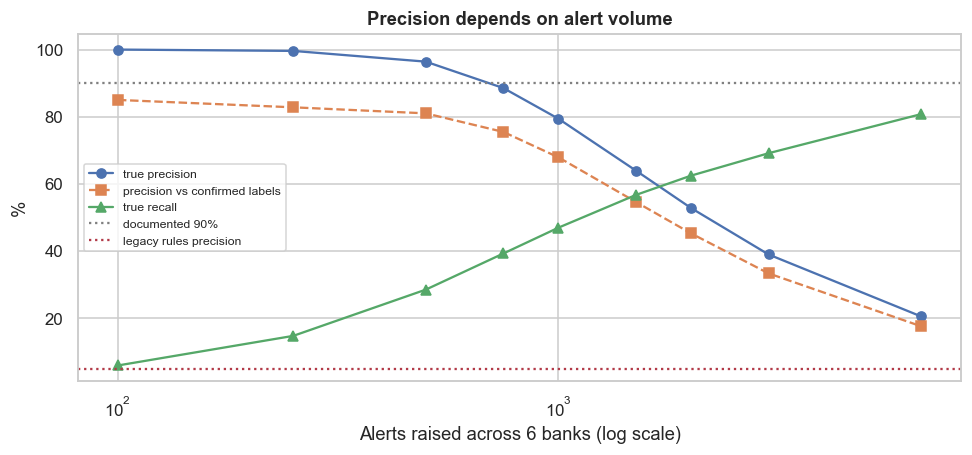

,% of accounts,true precision,precision vs confirmed labels,true recall
alerts,,,,
100,0.0694,1.0000,0.8500,0.0591
250,0.1736,0.9960,0.8280,0.1473
500,0.3472,0.9640,0.8100,0.2850
750,0.5208,0.8853,0.7547,0.3927
1000,0.6944,0.7940,0.6790,0.4695
1500,1.0417,0.6393,0.5460,0.5671
2000,1.3889,0.5280,0.4525,0.6245
3000,2.0833,0.3897,0.3333,0.6913
6662,4.6264,0.2050,0.1758,0.8078


In [13]:
o_t = np.argsort(-p_typ); conf = df.confirmed_mule.values; vol = []
for k in [100, 250, 500, 750, 1000, 1500, 2000, 3000, int(LEGACY.sum())]:
    top = o_t[:k]; vol.append((k, k / len(df) * 100, y[top].mean(), conf[top].mean(), y[top].sum() / y.sum()))
vol = pd.DataFrame(vol, columns=["alerts", "% of accounts", "true precision", "precision vs confirmed labels", "true recall"]).set_index("alerts")
k90 = vol[vol["true precision"] >= 0.9].index.max()
n_aud = int(np.ceil(1.96 ** 2 * 0.9 * 0.1 / 0.05 ** 2)); k_a = 500
aud = RNG.choice(o_t[:k_a], n_aud, replace=False); est = y[aud].mean(); lo, hi = proportion_confint(y[aud].sum(), n_aud, method="wilson")
print(f"Largest tested alert volume with true precision ≥ 90%: {k90} alerts ({k90 / len(df):.2%} of accounts)")
print(f"Audit design: n = 1.96² × 0.9 × 0.1 / 0.05² = {n_aud} alerts for ±5 pp. Simulated audit of the top {k_a}: precision {est:.1%} (Wilson {lo:.1%}–{hi:.1%}); "
      f"truth {y[o_t[:k_a]].mean():.1%}; confirmed-label view {conf[o_t[:k_a]].mean():.1%}")
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(vol.index, vol["true precision"] * 100, "o-", label="true precision"); ax.plot(vol.index, vol["precision vs confirmed labels"] * 100, "s--", label="precision vs confirmed labels")
ax.plot(vol.index, vol["true recall"] * 100, "^-", label="true recall"); ax.axhline(90, color="grey", ls=":", label="documented 90%")
ax.axhline(tr_t.loc["legacy bank rules", "precision"] * 100, color="#b23a48", ls=":", label="legacy rules precision")
ax.set_xscale("log"); ax.set_xlabel("Alerts raised across 6 banks (log scale)"); ax.set_ylabel("%"); ax.set_title("Precision depends on alert volume"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
vol.round(4)

**Takeaway:** - **Precision depends on volume.** It stays **≥ 90% up to about 500 alerts (0.35% of accounts)** at 29% recall. It falls to 79% at 1,000 alerts, 64% at 1,500 and 21% at the rules' volume, while recall rises from 6% to 81%.
- **Label noise understates precision.** Measured against *confirmed* labels, the top 500 look only **81%** precise vs **96%** in truth, because unconfirmed mules count as "false alarms".
- **Audit design:** an audit of **n = 139** randomly chosen alerts gives ±5 pp. Our simulated audit of the top 500 estimates **98.6% (Wilson 94.9–99.6%)**, consistent with the truth (96.4%).
- **(f) Business meaning:** "90 per cent positive alerts" should be quoted as "*90% precision at N alerts per month, verified by a random audit of 139 alerts*". Without the volume and the method, it cannot be compared with anything.

### 7.8 Who is missed? Recall by mule intensity

In [14]:
top = np.zeros(len(df), bool); top[o_t[:k1]] = True; mm = df._is_mule == 1
rk = df[mm].assign(caught=top[mm.values]).groupby("_sleeper").caught.agg(["sum", "size", "mean"])
rk.index = ["active mules", "sleepers (weak patterns)"]
ci = [proportion_confint(r["sum"], r["size"], method="wilson") for _, r in rk.iterrows()]; rk["CI low"], rk["CI high"] = [c[0] for c in ci], [c[1] for c in ci]
z, p = proportions_ztest(rk["sum"].values, rk["size"].values)
print(f"Recall at 1% alerts: active {rk['mean'].iloc[0]:.1%} vs sleepers {rk['mean'].iloc[1]:.1%} (z = {z:.1f}, p = {p:.2g})")
rk.round(4)

Recall at 1% alerts: active 71.6% vs sleepers 32.3% (z = 15.9, p = 3.5e-57)


,sum,size,mean,CI low,CI high
active mules,725,1013,0.7157,0.6871,0.7426
sleepers (weak patterns),219,678,0.3230,0.2889,0.3591


**Observation:** at a 1% alert budget the model catches **72% of active mules but only 32% of sleepers** (z = 15.9, p ≈ 1e-57). Sleepers show the same typologies at about a third of the intensity, so their accounts look close to genuine. **Business meaning:** sleeper mules are the hardest and probably the most numerous in reality. They need longer observation windows (90 → 180 days), network signals (links to known mule clusters), or periodic re-scoring, rather than a lower threshold that would flood investigators.

## 8. ML Section — brief

- **Model:** gradient boosting (histogram-based) on 11 raw + 9 typology features, trained on **confirmed** labels (what banks have), pooled across banks. No hyper-parameter tuning (per the brief).
- **Why not deep learning:** the documented model is unspecified. With ~1,400 positives, a tree ensemble on expert features is the standard choice, and it is explainable via the typology features, which matters for STR (suspicious transaction report) filings with FIU-IND.
- **Explainability for investigators:** each alert can list the typology rules it triggers (7.2), giving a human-readable reason aligned with FIU-IND red-flag indicators.

## 9. Business Translation — investigator workload and money intercepted

In [15]:
INV_MIN, INV_COST_HR = 45, 600                                            # minutes per alert investigation, ₹ per investigator-hour (assumptions, D-9-07)
mule_inflow = df.loc[df._is_mule == 1, "credits_90d_inr"].median() / 3     # median monthly inflow through a mule account
FREEZE = 0.30                                                             # share of a month's inflow stopped if frozen early (assumption)
NAT_ACCOUNTS = 1e8                                                        # scale: 10 crore accounts across adopting banks (assumption)
def plan(name, flagged_mask):
    k = flagged_mask.sum(); tp = (flagged_mask & (y == 1)).sum(); scale = NAT_ACCOUNTS / len(df)
    return (name, k * scale / 1e5, tp / k, tp * scale, (k - tp) * scale * INV_MIN / 60 / 1e5, (k - tp) * scale * INV_MIN / 60 * INV_COST_HR / 1e7, tp * scale * mule_inflow * FREEZE / 1e7)
top_leg = np.zeros(len(df), bool); top_leg[o_t[:int(LEGACY.sum())]] = True
top90 = np.zeros(len(df), bool); top90[o_t[:k90]] = True
wl = pd.DataFrame([plan("legacy bank rules", LEGACY.values), plan("model at the same alert volume as rules", top_leg), plan(f"model at ≥ 90% precision ({k90} alerts)", top90)],
                  columns=["policy (scaled to 10 crore accounts, per 90 days)", "alerts (lakh)", "precision", "mules caught", "wasted investigator-hours (lakh)", "₹ crore wasted on false alerts", "₹ crore mule inflow stopped"]).set_index("policy (scaled to 10 crore accounts, per 90 days)")
print(f"Median monthly inflow through a mule account ≈ ₹{mule_inflow:,.0f}")
wl.round(3)

Median monthly inflow through a mule account ≈ ₹29,870


,alerts (lakh),precision,mules caught,wasted investigator-hours (lakh),₹ crore wasted on false alerts,₹ crore mule inflow stopped
"policy (scaled to 10 crore accounts, per 90 days)",,,,,,
legacy bank rules,46.2640,0.0470,"218,750.0000",33.0570,198.3440,196.0220
model at the same alert volume as rules,46.2640,0.2050,"948,611.1110",27.5830,165.5000,850.0500
model at ≥ 90% precision (500 alerts),3.4720,0.9640,"334,722.2220",0.0940,0.5620,299.9450


**Takeaway (business reading):** scaled to **10 crore accounts per 90 days** (assumptions: 45 minutes per investigation, ₹600 per investigator-hour, 30% of a month's mule inflow stopped by an early freeze; median mule inflow ≈ ₹29,900/month):

| Policy | Alerts | Precision | Mules caught | Wasted investigator cost | Mule inflow stopped |
|---|---|---|---|---|---|
| **Legacy rules** | 46 lakh | 4.7% | ≈ 2.2 lakh | ≈ 33 lakh hours ≈ **₹198 crore** | ≈ **₹196 crore** |
| **Model, same alert volume** | 46 lakh | 20.5% | ≈ **9.5 lakh (4.3×)** | ₹166 crore | ≈ **₹850 crore** |
| **Model at the ≥ 90% precision point** | 3.5 lakh | 96% | ≈ 3.3 lakh | **₹0.6 crore** | ≈ ₹300 crore |

- **Reading:** the right operating point is set by **investigator capacity**. With today's teams, the high-precision point catches more mules than the rules with almost no wasted effort. As capacity grows, raising the alert volume catches more.
- All ₹ figures rest on the stated assumptions, and mule counts on the simulated 1.17% prevalence.

## 10. Recommendation and Decision

**Decision against the hypotheses:**
- **H1 ✅:** night activity is real, but bimodal.
- **H2 ✅:** typology features add AUC +0.062 and precision@500 +22 pp.
- **H3 ✅:** pooling wins in 6 of 6 banks.
- **H4 ✅:** a never-seen bank does *better* than with its own labels.
- **Limits:**
  - Unseen typologies are largely missed.
  - Sleepers are missed.
  - Precision without a stated volume is meaningless.

**I recommend:**
1. **Adopt the pooled, typology-based model** in place of legacy rules, including for banks with no labelled history. Use it as a **ranking**, with each bank choosing its alert volume from investigator capacity: start at the ≥ 90%-precision point (≈ 0.35% of accounts) and widen as capacity allows.
2. **Verify precision by audit:** each quarter, investigate a random sample of ~140 alerts per bank (and a small sample of non-alerts to estimate recall). Publish precision *with* the alert volume.
3. **Maintain the typology library as a programme:** a joint RBIH–bank–I4C process to add new patterns, retrain, and run a leave-one-typology-out check on each new one.
4. **Sleepers:** extend observation windows, add network links to known mule clusters, and re-score monthly.
5. **Customer protection:** an alert triggers enhanced due diligence, not an automatic freeze. Provide a fast appeal path for traders, farmers and gig workers (the hard negatives).

**KPIs:** audited alert precision at the operating volume (per bank); mules confirmed per investigator-day; recall estimated from non-alert audit samples; mule inflow frozen (₹); share of new typologies detected within 30 days of discovery; false-freeze complaints.

## 11. Risks, Limitations and Next Steps

- **Synthetic typologies:** our 8 patterns are a stylised subset of the documented 19 (later 90). Real mule behaviour shifts quickly (7.6 shows unseen patterns are partly missed). The typology library must be maintained jointly with banks, I4C and FIU-IND.
- **Label bias:** confirmed labels come from complaints and investigations, biased towards active and reported mules. Sleepers are both under-labelled and under-detected. Periodic random audits (7.7) are the only unbiased check.
- **Customer harm:** freezing a genuine account (a trader, a farmer receiving crop payments) causes real hardship. Alerts should trigger *investigation and enhanced due diligence*, with freezes only on investigator decision and a fast appeal path.
- **Data sharing and privacy:** a central model needs bank data under the DPDP Act and RBI outsourcing norms. Federated training (sharing model updates, not data) is the privacy-preserving alternative to test.
- **Precision claims:** "90% positive alerts" must always be quoted with the alert volume and the verification method (confirmed labels vs audit).

## 12. Appendix

| Quantity | Formula |
|---|---|
| Circular mean / R | θ̄ = atan2(mean sin θ, mean cos θ); R = √(C̄² + S̄²), θ = 2π·hour/24 |
| Rayleigh test | z = nR²; p ≈ e^(−z)(1 + (2z − z²)/(4n) − …) |
| Precision@k | true mules among the top k scores / k |
| Cochran's Q, I² | Q = Σwᵢ(pᵢ − p̄)², wᵢ = 1/Var(pᵢ); I² = (Q − df)/Q |
| Audit sample size | n = z²·p(1 − p)/E² (p = 0.9, E = 0.05 → 139) |
| Rank-biserial | r = 2U/(n₁n₂) − 1 |

| Term | Meaning |
|---|---|
| Mule account | An account used to receive and move fraud proceeds |
| Typology | An expert-defined behavioural pattern of mules |
| Sleeper mule | A mule with weak, intermittent activity |
| Pooled / central model | One model trained on data from many banks |
| Leave-one-bank-out | Testing on a bank never used in training |
| Alert precision | The share of alerts that are true mules |
| STR / FIU-IND | Suspicious transaction report / India's Financial Intelligence Unit |
| I4C | Indian Cyber Crime Coordination Centre |

**Source links:** https://www.business-standard.com/finance/personal-finance/explained-rbi-has-a-new-ai-tool-mulehunter-ai-to-reduce-digital-frauds-124120900250_1.html · https://www.business-standard.com/amp/industry/banking/15-more-banks-to-adopt-rbi-s-mulehunter-fraud-detection-tool-by-october-125080101845_1.html · https://www.medianama.com/2025/12/223-rti-23-banks-mulehunter-mule-accounts/ · https://clearingpost.com/insights/i4c-rbih-mulehunter-ai-banking-fraud-detection-may-2026/